In [1]:
# import packages
import platform
from pathlib import Path
import pandas as pd
import geopandas as gpd
import seaborn as sns
import calendar
import matplotlib.pyplot as plt
import pygris
import matplotlib.ticker as ticker
import ipywidgets as widgets
from IPython.display import display, clear_output

In [2]:
# Set Seaborn theme
sns.set_theme(
    style="whitegrid",
    context="notebook",
    palette='magma',
    font="Arial",
    rc={
        # Figure
        "figure.figsize": (10, 6),
        "figure.dpi": 120,

        # Background
        "axes.facecolor": "white",
        "figure.facecolor": "white",

        # Grid
        "axes.grid": True,
        "grid.color": "#E6E9EC",
        "grid.linestyle": "-",
        "grid.linewidth": 0.7,

        # Axes
        "axes.edgecolor": "#D5DADF",
        "axes.linewidth": 0.8,
        "axes.titlesize": 14,
        "axes.titleweight": "bold",
        "axes.labelsize": 11,

        # Ticks
        "xtick.labelsize": 10,
        "ytick.labelsize": 10,

        # Legend
        "legend.frameon": True,
        "legend.fontsize": 7,
        "legend.loc": "upper right",
        "legend.framealpha": 0.9,
        "legend.title_fontsize": 9,
        "legend.edgecolor": "#D5DADF",
        "legend.facecolor": "white",

        # Avoid scientific notation and offset notation
        "axes.formatter.useoffset": False,
        "axes.formatter.limits": (-100, 100),
    }
)

# Set default color cycle
plt.rcParams["axes.prop_cycle"] = plt.cycler(
    color=sns.color_palette('magma')
)

In [3]:
# import cleaned fire dataset

project_fldr = Path.cwd().parents[1]

raw_fldr = project_fldr / 'data' / 'raw'
processed_fldr = project_fldr / 'data' / 'processed'

# read in CSV
fire_shp_25 = gpd.read_file(processed_fldr / "fire_shp_25/fire_shp_25.shp")
fire_shp_25.info()

<class 'geopandas.geodataframe.GeoDataFrame'>
RangeIndex: 521 entries, 0 to 520
Data columns (total 23 columns):
 #   Column      Non-Null Count  Dtype   
---  ------      --------------  -----   
 0   YEAR_       521 non-null    float64 
 1   STATE       521 non-null    str     
 2   AGENCY      521 non-null    str     
 3   UNIT_ID     521 non-null    str     
 4   FIRE_NAME   521 non-null    str     
 5   INC_NUM     521 non-null    str     
 6   IRWINID     469 non-null    str     
 7   ALARM_DATE  521 non-null    str     
 8   CONT_DATE   514 non-null    str     
 9   C_METHOD    521 non-null    int32   
 10  CAUSE       521 non-null    int32   
 11  OBJECTIVE   521 non-null    float64 
 12  GIS_ACRES   521 non-null    float64 
 13  COMPLEX_ID  17 non-null     str     
 14  COMPLEX_NA  17 non-null     str     
 15  COMMENTS    120 non-null    str     
 16  FIRE_NUM    0 non-null      object  
 17  Shape_Leng  521 non-null    float64 
 18  Shape_Area  521 non-null    float64 
 19  

In [4]:
fire_shp_25['CONT_DATE'].value_counts()

CONT_DATE
2025/09/02 00:00:00+00    10
2025/08/27 00:00:00+00    10
2025/07/07 00:00:00+00     9
2025/07/05 00:00:00+00     9
2025/06/11 00:00:00+00     8
                          ..
2025/12/23 00:00:00+00     1
2025/12/06 00:00:00+00     1
2025/12/01 00:00:00+00     1
2025/07/28 00:00:00+00     1
2025/07/11 00:00:00+00     1
Name: count, Length: 209, dtype: int64

In [5]:
# make alarm date column datetime
fire_shp_25['ALARM_DATE'] = pd.to_datetime(fire_shp_25['ALARM_DATE'])
fire_shp_25['CONT_DATE'] = pd.to_datetime(fire_shp_25['CONT_DATE'])
fire_shp_25['Alarm Mo_1'] = pd.Categorical(
    values = fire_shp_25['Alarm Mo_1'],
    categories=calendar.month_abbr[1:]
)

In [6]:
#map cause to code
code_to_cause = {
    1: "Lightning",
    2: "Equipment Use",
    3: "Smoking",
    4: "Campfire",
    5: "Debris",
    6: "Railroad",
    7: "Arson",
    8: "Playing with fire",
    9: "Miscellaneous",
    10: "Vehicle",
    11: "Powerline",
    12: "Firefighter Training",
    13: "Non-Firefighter Training",
    14: "Unknown/Unidentified",
}

fire_shp_25['CAUSE_NAME'] = fire_shp_25['CAUSE'].map(code_to_cause)
fire_shp_25['CAUSE_NAME'].head(10)

0    Unknown/Unidentified
1    Unknown/Unidentified
2               Lightning
3               Lightning
4    Unknown/Unidentified
5    Unknown/Unidentified
6               Lightning
7    Unknown/Unidentified
8               Lightning
9    Unknown/Unidentified
Name: CAUSE_NAME, dtype: str

In [ ]:
# Set the "selected" values
alarm_start_date = "2020-01-01" #alarm date dropdown range
alarm_end_date = "2025-12-31"
cont_start_date = "2020-01-01" #containment date dropdown range
cont_end_date = "2025-12-31"
cause = 'Lightning'
size = 0

# Subset the data
fire_subset = fire_shp_25.loc[
    (fire_shp_25['ALARM_DATE'] >= alarm_start_date) &  # Start date
    (fire_shp_25['ALARM_DATE'] <= alarm_end_date) &    # End date
    (fire_shp_25['CONT_DATE'] >= cont_start_date) &    # Containment start date
    (fire_shp_25['CONT_DATE'] <= cont_end_date) &      # Containment end date
    (fire_shp_25['CAUSE_NAME']==(cause)) &
    (fire_shp_25['Shape_Area'] >= size),  
]

fire_subset.head()


,YEAR_,STATE,AGENCY,UNIT_ID,FIRE_NAME,INC_NUM,IRWINID,ALARM_DATE,CONT_DATE,C_METHOD,...,COMPLEX_NA,COMMENTS,FIRE_NUM,Shape_Leng,Shape_Area,GlobalID,Alarm Mont,Alarm Mo_1,geometry,CAUSE_NAME
2,2025.0,CA,USF,SNF,GARNET,00001684,{68B988A1-C190-4F0C-9BEA-A658D389D167},2025-08-24 00:00:00+00:00,2025-10-23 00:00:00+00:00,3,...,NaN,NaN,None,234717.355087,2.428892e+08,{DDD0B278-7655-4F20-829D-FEEEF1DC935F},8.0,Aug,"MULTIPOLYGON (((89617.826 -122364.58, 89614.97...",Lightning
3,2025.0,CA,CDF,FKU,SALT,00018739,{7F4A1474-6439-44F3-8F0D-083DCFD33639},2025-09-02 00:00:00+00:00,2025-09-17 00:00:00+00:00,7,...,NaN,Park incident clipped out per BEU,None,90080.360959,1.034115e+08,{6817A72C-90CF-4CD4-8F26-2B9622F1F140},9.0,Sep,"POLYGON ((-31970.799 -229822.278, -31947.464 -...",Lightning
6,2025.0,CA,USF,SHF,GREEN,00000560,{F3A7DBCB-C6C0-442A-A9CA-AA18CC9EF80A},2025-07-02 00:00:00+00:00,2025-08-14 00:00:00+00:00,3,...,NaN,NaN,None,64406.516691,7.697926e+07,{78D040B5-089A-45E1-91D9-9904E116CA0D},7.0,Jul,"MULTIPOLYGON (((-180595.457 310065.68, -180583...",Lightning
8,2025.0,CA,USF,SRF,DILLON,00000715,{0140F0B6-2F32-4651-9008-E5AE2C38F547},2025-08-25 00:00:00+00:00,2025-11-06 00:00:00+00:00,7,...,NaN,NaN,None,76359.245741,4.827647e+07,{FF4F07C5-FB4C-45E2-8982-A51A936094BE},8.0,Aug,"MULTIPOLYGON (((-293706.391 397689.528, -29370...",Lightning
10,2025.0,CA,CDF,TCU,6-5,00012060,{8AA404C0-7A0B-46AA-8302-65E9E8EEC88B},2025-09-02 00:00:00+00:00,2025-09-13 00:00:00+00:00,3,...,TCU SEPTEMBER LIGHTNING,NaN,None,50111.368447,2.815802e+07,{B53D79E2-2269-41C2-8F91-9EC4ADBD5F78},9.0,Sep,"POLYGON ((-37080.218 -17859.032, -37087.475 -1...",Lightning


<class 'matplotlib.axes._axes.Axes'>


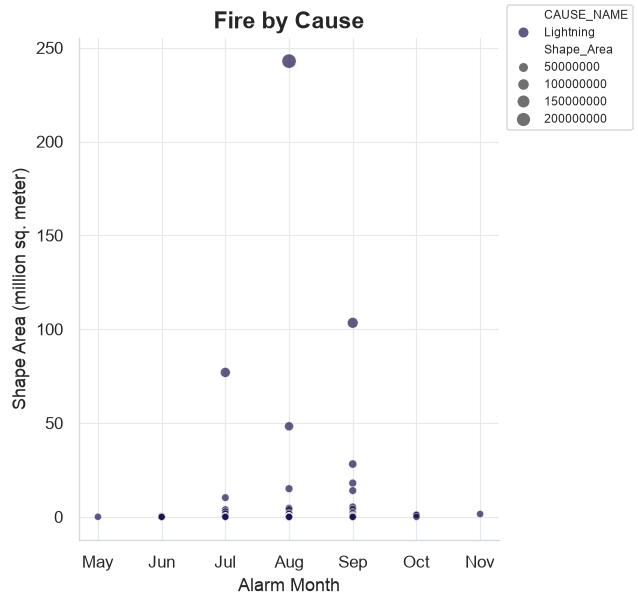

In [8]:

#Create a plot of selected fire by cause
the_plot = sns.relplot(
    data = fire_subset,
    x='Alarm Mo_1',
    y='Shape_Area',
    hue='CAUSE_NAME',
    size='Shape_Area',
    alpha=0.7,
    legend = True
)

#Set plot title and axis labels
the_plot.set_axis_labels('Alarm Month', 'Shape Area (million sq. meter)')
the_plot.set(title='Fire by Cause')

#Clean up the legend
if the_plot.legend is not None:
    sns.move_legend(
        the_plot,
        loc='upper right',
        frameon=True
    )
    leg = the_plot.legend
    leg.get_title().set_ha('left')
    leg._legend_box.align = 'left'

#Set y-axis to use scientific notation
the_plot = plt.gca()
the_plot.yaxis.set_major_formatter(
    ticker.FuncFormatter(lambda x, pos: f'{x/1_000_000:g}')
)

print(type(the_plot))
#Display
the_plot;

In [ ]:
### Plot as a function
def plot_fire_cause(alarm_start_date = "2020-01-01", #alarm date dropdown range
                    alarm_end_date = "2025-12-31",
                    cont_start_date = "2020-01-01", #containment date dropdown range
                    cont_end_date = "2025-12-31",
                    cause = 'Lightning',
                    size = 0):
    # Subset the data
    print("plot_fire_cause called")
    fire_subset = fire_shp_25.loc[
        (fire_shp_25['ALARM_DATE'] >= alarm_start_date) &  # Start date
        (fire_shp_25['ALARM_DATE'] <= alarm_end_date) &    # End date
        (fire_shp_25['CONT_DATE'] >= cont_start_date) &    # Containment start date
        (fire_shp_25['CONT_DATE'] <= cont_end_date) &      # Containment end date
        (fire_shp_25['CAUSE_NAME']==(cause)) &
        (fire_shp_25['Shape_Area'] >= size),
        ]   

    #Create a plot of selected fire by cause
    the_plot = sns.relplot(
        data = fire_subset,
        x='Alarm Mo_1',
        y='Shape_Area',
        hue='CAUSE_NAME',
        size='Shape_Area',
        alpha=0.7,
        legend = True
    )

    #Set plot title and axis labels
    the_plot.set_axis_labels('Alarm Month', 'Shape Area (million sq. meter)')
    the_plot.set(title='Fire by Cause')

    # Clean up the legend
    if the_plot.legend is not None:
        sns.move_legend(
            the_plot,
            loc='upper right',
            frameon=True
        )

        leg = the_plot.legend
        leg.get_title().set_ha('left')
        leg._legend_box.align = 'left'
        leg.get_title().set_text('Cause')


    #Set y-axis to use scientific notation
    ax = the_plot.ax
    ax.yaxis.set_major_formatter(
    ticker.FuncFormatter(lambda x, pos: f'{x/1_000_000:g}')
    )
    
    #return the plot
    print("Number of axes:", len(the_plot.figure.axes))
    return the_plot
    
    
    

plot_fire_cause called
Number of axes: 1


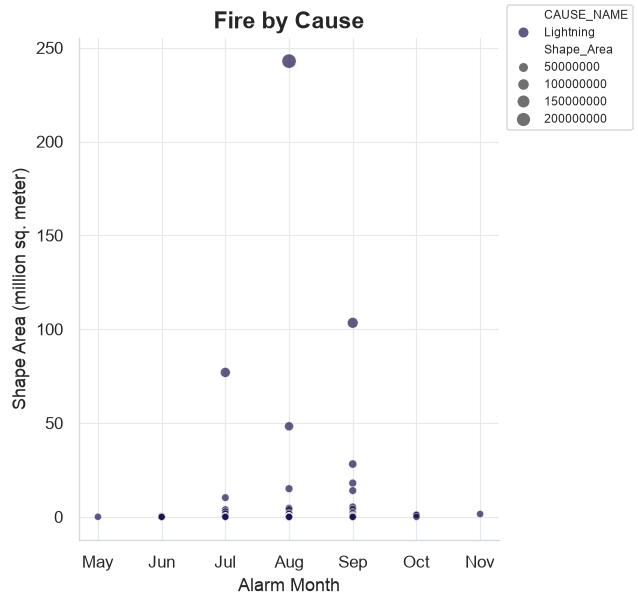

In [106]:
#Apply the function
plot_fire_cause(cause='Lightning');

In [10]:
#Create a dropdown widget from fire causes
cause_list = fire_shp_25['CAUSE_NAME'].dropna().unique()
cause_dropdown = widgets.Dropdown(
    options=cause_list,
    value=cause_list[0],
    description='Cause:',
)
#size dropdown widget
size_dropdown = widgets.Dropdown(
    options=[
        ('All sizes', 0),
        ('100+ million sq. meter', 100000000),
        ('500+ million sq. meter', 500000000),
        ('1,000+ million sq. meter', 1000000000),
        ('5,000+ million sq. meter', 5000000000)
    ],
    value=0,
    description='Size:',
)

In [ ]:
#Create a date slider from the date range - start
start_dates = fire_shp_25['ALARM_DATE'].sort_values().unique()
start_date_options = [(date.strftime("%Y/%m/%d"), date) for date in start_dates]

#Create a date slider from the date range - end
cont_dates = fire_shp_25['CONT_DATE'].dropna().sort_values().unique()
cont_date_options = [(date.strftime("%Y/%m/%d"), date) for date in cont_dates]

# Create a date range slider with start date labelled on the left and end date on the right
date_slider_start = widgets.SelectionRangeSlider(
    options = start_date_options,
    index = (0,len(start_date_options) - 1),
    description = 'Start Date Range:',
    layout = widgets.Layout(width='75%')
)

date_slider_cont = widgets.SelectionRangeSlider(
    options = cont_date_options,
    index = (0,len(cont_date_options) - 1),
    description = 'End Date range:',
    layout = widgets.Layout(width='75%')
)

In [12]:
# Create an output area for the plot
plot_output = widgets.Output()

# Function to update the plot
def update_data_or_plot(change=None):
    print("Update function called")
    #Direct output to the plot_output widget
    with plot_output:
        # Clear the previous plot
        clear_output(wait=True)

        # Generate the new plot
        g = plot_fire_cause(
            alarm_start_date=date_slider_start.value[0],
            alarm_end_date=date_slider_start.value[1],
            cont_start_date=date_slider_cont.value[0],
            cont_end_date=date_slider_cont.value[1],
            cause=cause_dropdown.value,
            size=size_dropdown.value,
        )

        # Explicitly display the plot
        display(g.figure)
        plt.close(g.figure)

# Attach observers
date_slider_start.observe(update_data_or_plot, names='value')
date_slider_cont.observe(update_data_or_plot, names='value')
cause_dropdown.observe(update_data_or_plot, names='value')
size_dropdown.observe(update_data_or_plot, names='value')

# Display the widgets and plot together
display(
    widgets.VBox([
        date_slider_start,
        date_slider_cont,
        cause_dropdown,
        size_dropdown,
        plot_output
    ])
)

# Generate the initial plot
update_data_or_plot()

Update function called
